# <center>Hyperparamater tuning</center>

# Modules
To enable autoreloading of all modules, it is necessary to install IPython by executing the following command: **pip install ipython**

Example of module importation:
```python
from Modules import data_manipulation_module as dmm
```

| Modul names                   | Description                                             |
|-------------------------------|---------------------------------------------------------|
| data_manipulation_module      | Functions for data manipulation                         |
| nts_classification_module     | Functions for non-time series classification algorithms |
| ts_classification_module      | Functions for time series classification algorithms     |
| validation_and_results_module | Functions for validation and results                    |
| param_tuning_module           | Functions for parameter tuning                          |
| dim_reduction_module          | Functions for dimensionality reduction                  |
| plots_module                  | Functions for plotting                                  |

In [4]:
#autoreload all the modules (no need to rerun the module importation statement to implement the changes)
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## 1. Non-time series classifiers (Full dataset)
### 1.1. Data loading

In [2]:
import glob
import pandas as pd

#beacuse of k-nn
from warnings import simplefilter
simplefilter(action='ignore', category = FutureWarning)

#Numpy version check
import numpy as np
np.__version__
#delete the comment before pip if the version is not 1.21.4
#pip install --upgrade numpy==1.21.4 --user

'1.21.4'

In [5]:
from Modules import data_manipulation_module as dmm

In [6]:
#Saving the files names
NP_csv_files = glob.glob('/tf/notebooks/DatasCSV/NP/*.csv')
KT_csv_files = glob.glob('/tf/notebooks/DatasCSV/KT/*.csv')
SU_csv_files = glob.glob('/tf/notebooks/DatasCSV/SU/*.csv')

NP_csv_files = sorted(NP_csv_files)
KT_csv_files = sorted(KT_csv_files)
SU_csv_files = sorted(SU_csv_files)

In [7]:
#Loading_data(files, separator)
NP_df_list = dmm.Loading_data(NP_csv_files, ";", None)
KT_df_list = dmm.Loading_data(KT_csv_files, ";", None)
SU_df_list = dmm.Loading_data(SU_csv_files, ";", None)

In [8]:
#Target vairable files loading
NP_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Needle_Passing.txt', " ", None)
KT_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Knot_Tying.txt', " ", None)
SU_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Suturing.txt', " ", None)

In [9]:
#Selecting the GRS as the target variable (binary classification)
#If the GRS score is below 16 (with a maximum possible score of 30), the participant is classified as 0, indicating the novice class
#Conversely, a score of 16 or higher results in a classification of 1, indicating the expert class
NP_class_binary = NP_class.copy()
KT_class_binary = KT_class.copy()
SU_class_binary = SU_class.copy()

NP_class_multi = NP_class.copy()
KT_class_multi = KT_class.copy()
SU_class_multi = SU_class.copy()

NP_class_binary["GRS"] = np.where(NP_class["GRS"] < 16, 0, 1)
KT_class_binary["GRS"] = np.where(KT_class["GRS"] < 16, 0, 1)
SU_class_binary["GRS"] = np.where(SU_class["GRS"] < 16, 0, 1)

NP_class_multi["GRS"] = NP_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))
KT_class_multi["GRS"] = KT_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))
SU_class_multi["GRS"] = SU_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))

### 1.2. ApEn

In [10]:
#Copying the header from the previous dataframes and using this dataframe to create the new dataframes for storing non-time series datas
feature_names = NP_df_list[0].columns
    
NP_ApEn = pd.DataFrame(columns = feature_names)
KT_ApEn = pd.DataFrame(columns = feature_names)
SU_ApEn = pd.DataFrame(columns = feature_names)

In [11]:
#This may require a considerable amount of time to execute.
#Approximate_entropy(df_list, return_ApEn)
NP_ApEn = dmm.Approximate_entropy(NP_df_list, NP_ApEn)
KT_ApEn = dmm.Approximate_entropy(KT_df_list, KT_ApEn)
SU_ApEn = dmm.Approximate_entropy(SU_df_list, SU_ApEn)

In [12]:
#Appending the target variables to the data
#Target_append(df_class, return_ApEn, class_column_name)
NP_ApEn_binary = NP_ApEn.copy()
KT_ApEn_binary = KT_ApEn.copy()
SU_ApEn_binary = SU_ApEn.copy()

NP_ApEn_multi = NP_ApEn.copy()
KT_ApEn_multi = KT_ApEn.copy()
SU_ApEn_multi = SU_ApEn.copy()

NP_ApEn_binary = dmm.Target_append(NP_class_binary, NP_ApEn_binary, "GRS")
KT_ApEn_binary = dmm.Target_append(KT_class_binary, KT_ApEn_binary, "GRS")
SU_ApEn_binary = dmm.Target_append(SU_class_binary, SU_ApEn_binary, "GRS")

NP_ApEn_multi = dmm.Target_append(NP_class_multi, NP_ApEn_multi, "GRS")
KT_ApEn_multi = dmm.Target_append(KT_class_multi, KT_ApEn_multi, "GRS")
SU_ApEn_multi = dmm.Target_append(SU_class_multi, SU_ApEn_multi, "GRS")

In [13]:
#Features and target variable
NP_X_ApEn, NP_Y_ApEn_binary = dmm.Features_target(NP_ApEn_binary)
KT_X_ApEn, KT_Y_ApEn_binary = dmm.Features_target(KT_ApEn_binary)
SU_X_ApEn, SU_Y_ApEn_binary = dmm.Features_target(SU_ApEn_binary)

#Multiclass version
NP_X_ApEn, NP_Y_ApEn_multi = dmm.Features_target(NP_ApEn_multi)
KT_X_ApEn, KT_Y_ApEn_multi = dmm.Features_target(KT_ApEn_multi)
SU_X_ApEn, SU_Y_ApEn_multi = dmm.Features_target(SU_ApEn_multi)

---
## 2. Non-time series classifiers (Gestures)
### 2.1. Data loading

In [17]:
NP_gesture_files = glob.glob('/tf/notebooks/Gestures/NP/*.csv')
KT_gesture_files = glob.glob('/tf/notebooks/Gestures/KT/*.csv')
SU_gesture_files = glob.glob('/tf/notebooks/Gestures/SU/*.csv')

NP_gesture_files = sorted(NP_gesture_files)
KT_gesture_files = sorted(KT_gesture_files)
SU_gesture_files = sorted(SU_gesture_files)

In [18]:
NP_gesture_df_list = dmm.Loading_data(NP_gesture_files, ";", None)
KT_gesture_df_list = dmm.Loading_data(KT_gesture_files, ";", None)
SU_gesture_df_list = dmm.Loading_data(SU_gesture_files, ";", None)

### 2.2. Dataset division by gestures

In [19]:
Needle_Passing_gestures = [1, 2, 3, 4, 5, 6, 8, 11]
Knot_Tying_gestures = [1 , 11 , 12 , 13 , 14 , 15]
Suturing_gestures = [1, 2, 3, 4, 5, 6, 8, 9, 10, 11]

number_of_gestures = 15
feature_names = NP_df_list[0].columns

In [20]:
NP_gestures = dmm.Gestures_data_splitting(number_of_gestures, feature_names, Needle_Passing_gestures, NP_gesture_df_list, NP_df_list)
KT_gestures = dmm.Gestures_data_splitting(number_of_gestures, feature_names, Knot_Tying_gestures, KT_gesture_df_list, KT_df_list)
SU_gestures = dmm.Gestures_data_splitting(number_of_gestures, feature_names, Suturing_gestures, SU_gesture_df_list, SU_df_list)

In [18]:
NP_gestures_ApEn_binary = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, NP_gestures, feature_names, NP_class_binary, 2)
KT_gestures_ApEn_binary = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, KT_gestures, feature_names, KT_class_binary, 2)
SU_gestures_ApEn_binary = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, SU_gestures, feature_names, SU_class_binary, 2)

NP_gestures_ApEn_multi = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, NP_gestures, feature_names, NP_class_multi, 2)
KT_gestures_ApEn_multi = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, KT_gestures, feature_names, KT_class_multi, 2)
SU_gestures_ApEn_multi = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, SU_gestures, feature_names, SU_class_multi, 2)

In [19]:
print("Binary:")
NP_gestures_X_ApEn, NP_gestures_Y_ApEn_binary, Needle_Passing_gestures_binary = dmm.Gestures_features_target(NP_gestures_ApEn_binary, Needle_Passing_gestures, 1)
KT_gestures_X_ApEn, KT_gestures_Y_ApEn_binary, Knot_Tying_gestures_binary = dmm.Gestures_features_target(KT_gestures_ApEn_binary, Knot_Tying_gestures, 1)
SU_gestures_X_ApEn, SU_gestures_Y_ApEn_binary, Suturing_gestures_binary = dmm.Gestures_features_target(SU_gestures_ApEn_binary, Suturing_gestures, 1)

print("\nMulti:")
NP_gestures_X_ApEn, NP_gestures_Y_ApEn_multi, Needle_Passing_gestures_multi = dmm.Gestures_features_target(NP_gestures_ApEn_multi, Needle_Passing_gestures, 1)
KT_gestures_X_ApEn, KT_gestures_Y_ApEn_multi, Knot_Tying_gestures_multi = dmm.Gestures_features_target(KT_gestures_ApEn_multi, Knot_Tying_gestures, 1)
SU_gestures_X_ApEn, SU_gestures_Y_ApEn_multi, Suturing_gestures_multi = dmm.Gestures_features_target(SU_gestures_ApEn_multi, Suturing_gestures, 1)

Binary:
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 11]
Final gestures for the task: [1, 11, 12, 13, 14, 15]
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 9, 10, 11]

Multi:
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 11]
Final gestures for the task: [1, 11, 12, 13, 14, 15]
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 9, 10, 11]


----
## 3. Hyperparameter tuning (Non-time series)

In [12]:
%set_env TF_ENABLE_ONEDNN_OPTS=0

env: TF_ENABLE_ONEDNN_OPTS=0


In [15]:
#Querying the number of CPUs.
import os
n_cpu = os.cpu_count()
print(n_cpu)

60


In [13]:
from Modules import param_tuning_module as ptm
from Modules import validation_and_results_module as vrm
from Modules import plots_module as pm

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import LeaveOneOut

In [17]:
models = {
        'decision_tree': {
            'model': DecisionTreeClassifier(),
            'params': {
                'criterion':  ['gini', 'entropy'],
                'max_depth':  [None, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                'max_features': [None, 'sqrt', 'log2', 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
                'splitter': ['best', 'random'],
                'random_state': [0]
                     }
        },
        'k-NN': {
            'model': KNeighborsClassifier(),
            'params': {
                #+1: to included the last value in the range.
                'n_neighbors' : range(1, 5),
                'weights' : ['uniform', 'distance'],
                'metric' : ['euclidean', 'manhattan', 'minkowski']
                      }
        },
        'logistic_regression': {
            'model': LogisticRegression(),
            'params': {
                #Delete the comment before multi_class for multiclassification
                #'multi_class': ['ovr'], #For multiclass
                'penalty' : ["l1", "l2"],
                'solver' : ["newton-cg", "lbfgs", "liblinear", "sag", "saga"],
                'C':  [0.1, 0.5, 1, 5, 10, 50,  100, 500, 1000],
                #The maximum iteration value had to be increased (to 10000) due to convergence warnings.
                'max_iter': [10000],
                'random_state' : [0]
                    }
        },
        'SVM': {
            'model': svm.SVC(),
            'params': {
                #Delete the comment before multi_class for multiclassification
                #'decision_function_shape': ['ovo'], #For multiclass
                'C': [1000, 500, 100, 50, 10, 5, 1, 0.5, 0.1],
                'kernel' : ['poly', 'rbf', 'sigmoid', 'linear'],
                'gamma': ['auto', 'scale', 1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001],
                'random_state' : [0]
                       }
        
         }
}

In [18]:
test_size = [0.1, 0.2, 0.3, 0.4]

In [180]:
#Hyperparameter_tuning(models, metric, X, Y, test_sizes, cv, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
    #metric: "accuracy", "recall_micro", "recall_macro", "recall_weighted", "precision_micro", "precision_macro", "precision_weighted", "f1_micro", "f1_macro", "f1_weighted"
    #test_size: list
    #cv: int, LeaveOneOut()
    #standardize: "No", "Non-time"
    #calculate_maximum_neighbors: True, False
        #True: computes the maximum value of the neighbors and employs this value for model creation
    #show_results: True, False
    #n_jobs: int
NP_accuracy, NP_estimator = ptm.Hyperparameter_tuning(models, "f1_macro", NP_X_ApEn, NP_Y_ApEn_binary, test_size, 5, feature_names, "No", True, True, -1)

Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 20


,Model,Validation score,Test score,Parameter
0,decision_tree,0.622381,1.0,"DecisionTreeClassifier(criterion='entropy', max_features=0.7, random_state=0)"
1,k-NN,0.494048,1.0,"KNeighborsClassifier(metric='euclidean', n_neighbors=1)"
2,logistic_regression,0.571429,1.0,"LogisticRegression(C=50, max_iter=10000, random_state=0, solver='newton-cg')"
3,SVM,0.543333,1.0,"SVC(C=1000, kernel='poly', random_state=0)"




Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 17


,Model,Validation score,Test score,Parameter
0,decision_tree,0.737143,0.777778,"DecisionTreeClassifier(criterion='entropy', max_depth=2, max_features=0.3,\n random_state=0)"
1,k-NN,0.598810,0.777778,"KNeighborsClassifier(metric='euclidean', n_neighbors=9, weights='distance')"
2,logistic_regression,0.658333,0.777778,"LogisticRegression(C=50, max_iter=10000, random_state=0, solver='liblinear')"
3,SVM,0.709048,0.777778,"SVC(C=1000, kernel='poly', random_state=0)"




Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15


,Model,Validation score,Test score,Parameter
0,decision_tree,0.933333,0.649351,"DecisionTreeClassifier(max_depth=1, random_state=0)"
1,k-NN,0.712381,0.678571,"KNeighborsClassifier(metric='euclidean', n_neighbors=4, weights='distance')"
2,logistic_regression,0.780000,0.584615,"LogisticRegression(C=50, max_iter=10000, penalty='l1', random_state=0,\n solver='liblinear')"
3,SVM,0.780000,0.584615,"SVC(C=1000, gamma='auto', random_state=0)"




Test size (0.4): The n_neighbors parameter value has been modified. The new maximum value: 12


,Model,Validation score,Test score,Parameter
0,decision_tree,0.850000,0.621053,"DecisionTreeClassifier(criterion='entropy', random_state=0, splitter='random')"
1,k-NN,0.746667,0.555556,"KNeighborsClassifier(metric='euclidean', n_neighbors=3)"
2,logistic_regression,0.826667,0.555556,"LogisticRegression(C=10, max_iter=10000, random_state=0, solver='liblinear')"
3,SVM,0.813333,0.555556,"SVC(C=1000, random_state=0)"


In [26]:
#Multiple_cv_hyperparameter_tuning(cv_start, cv_end, models, metric, X, Y, test_sizes, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
NP_scores, NP_estimators, NP_cvs = ptm.Multiple_cv_hyperparameter_tuning(2, 6, models, "f1_macro", NP_X_ApEn, NP_Y_ApEn_binary, test_size, feature_names, "No", True, False, -1)

CV: 2
Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 12
Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 11
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 9
Test size (0.4): The n_neighbors parameter value has been modified. The new maximum value: 8
CV: 3
Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 16
Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 14
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 12
Test size (0.4): The n_neighbors parameter value has been modified. The new maximum value: 10
CV: 4
Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 18
Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 16
Test size (0.3): The n_neighbors parameter v

In [29]:
#Best_param_tuning_accuracies(acc, estimator, cvs, test_size, class_alg)
NP_best_scores = dmm.Best_hyperparameter_tuning_scores(NP_scores, NP_estimators, NP_cvs, test_size, ['Decision Tree', 'k-NN', 'Logistic Regression', 'SVM'])

Test size: 0.1


,Classification algorithm,Best test score,Best estimator,Best cv
0,Decision Tree,1.0,"DecisionTreeClassifier(max_features=0.7, random_state=0, splitter='random')",3
1,k-NN,1.0,"KNeighborsClassifier(metric='euclidean', n_neighbors=1)",2
2,Logistic Regression,1.0,"LogisticRegression(C=100, max_iter=10000, random_state=0, solver='liblinear')",2
3,SVM,1.0,"SVC(C=1000, gamma=1, random_state=0)",2


Test size: 0.2


,Classification algorithm,Best test score,Best estimator,Best cv
0,Decision Tree,0.777778,"DecisionTreeClassifier(criterion='entropy', max_features=0.7, random_state=0,\n splitter='random')",2
1,k-NN,0.777778,"KNeighborsClassifier(metric='euclidean', n_neighbors=1)",2
2,Logistic Regression,0.777778,"LogisticRegression(C=100, max_iter=10000, random_state=0, solver='liblinear')",2
3,SVM,0.777778,"SVC(C=500, gamma=0.05, kernel='sigmoid', random_state=0)",2


Test size: 0.3


,Classification algorithm,Best test score,Best estimator,Best cv
0,Decision Tree,0.678571,"DecisionTreeClassifier(max_features=0.3, random_state=0)",2
1,k-NN,0.678571,"KNeighborsClassifier(metric='euclidean', n_neighbors=1)",2
2,Logistic Regression,0.678571,"LogisticRegression(C=50, max_iter=10000, random_state=0, solver='newton-cg')",3
3,SVM,0.584615,"SVC(C=1000, gamma=0.05, kernel='sigmoid', random_state=0)",2


Test size: 0.4


,Classification algorithm,Best test score,Best estimator,Best cv
0,Decision Tree,0.700000,"DecisionTreeClassifier(max_features=0.7, random_state=0)",2
1,k-NN,0.555556,"KNeighborsClassifier(metric='euclidean', n_neighbors=3)",2
2,Logistic Regression,0.555556,"LogisticRegression(C=50, max_iter=10000, random_state=0, solver='liblinear')",2
3,SVM,0.555556,"SVC(C=1000, gamma='auto', random_state=0)",2


### Diagrams
#### column diagram

In [31]:
score, estimatior = ptm.Hyperparameter_tuning(models, 'accuracy', NP_X_ApEn, NP_Y_ApEn_binary, \
                                             test_size, 2, feature_names, "No", True, True, -1)

Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 12


,Model,Validation score,Test score,Parameter
0,decision_tree,0.762821,0.666667,"DecisionTreeClassifier(criterion='entropy', max_features=0.2, random_state=0,\n splitter='random')"
1,k-NN,0.759615,1.000000,"KNeighborsClassifier(metric='euclidean', n_neighbors=1)"
2,logistic_regression,0.679487,0.666667,"LogisticRegression(C=0.1, max_iter=10000, random_state=0, solver='newton-cg')"
3,SVM,0.679487,1.000000,"SVC(C=1000, gamma='auto', kernel='poly', random_state=0)"




Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 11


,Model,Validation score,Test score,Parameter
0,decision_tree,0.863636,0.833333,"DecisionTreeClassifier(criterion='entropy', max_features=0.7, random_state=0,\n splitter='random')"
1,k-NN,0.818182,0.833333,"KNeighborsClassifier(metric='euclidean', n_neighbors=1)"
2,logistic_regression,0.727273,0.833333,"LogisticRegression(C=100, max_iter=10000, random_state=0, solver='liblinear')"
3,SVM,0.772727,0.833333,"SVC(C=500, gamma=0.05, kernel='sigmoid', random_state=0)"




Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 9


,Model,Validation score,Test score,Parameter
0,decision_tree,0.788889,0.777778,"DecisionTreeClassifier(max_features=0.3, random_state=0)"
1,k-NN,0.788889,0.777778,"KNeighborsClassifier(metric='euclidean', n_neighbors=1)"
2,logistic_regression,0.733333,0.666667,"LogisticRegression(C=500, max_iter=10000, random_state=0, solver='newton-cg')"
3,SVM,0.783333,0.666667,"SVC(C=1000, gamma=0.05, kernel='sigmoid', random_state=0)"




Test size (0.4): The n_neighbors parameter value has been modified. The new maximum value: 8


,Model,Validation score,Test score,Parameter
0,decision_tree,0.8125,0.833333,"DecisionTreeClassifier(max_features=0.7, random_state=0)"
1,k-NN,0.8125,0.666667,"KNeighborsClassifier(metric='euclidean', n_neighbors=2)"
2,logistic_regression,0.9375,0.666667,"LogisticRegression(C=50, max_iter=10000, random_state=0, solver='liblinear')"
3,SVM,0.8750,0.666667,"SVC(C=1000, gamma='auto', random_state=0)"


In [32]:
score

[[0.6666666666666666,
  0.8333333333333334,
  0.7777777777777778,
  0.8333333333333334],
 [1.0, 0.8333333333333334, 0.7777777777777778, 0.6666666666666666],
 [0.6666666666666666,
  0.8333333333333334,
  0.6666666666666666,
  0.6666666666666666],
 [1.0, 0.8333333333333334, 0.6666666666666666, 0.6666666666666666]]

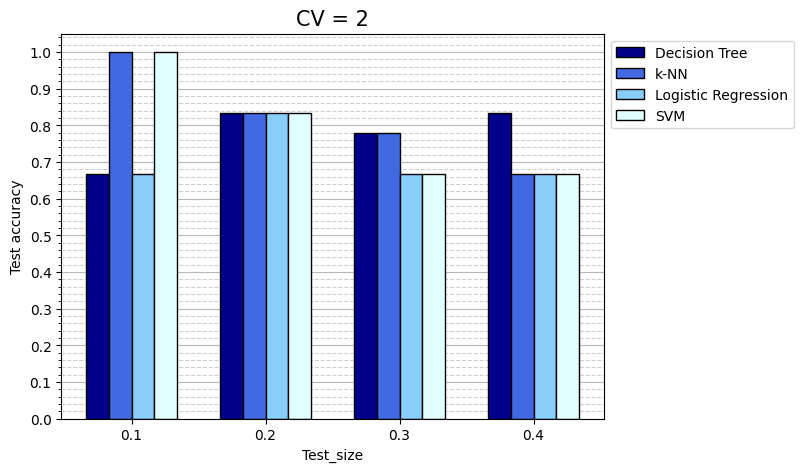

In [33]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([score[0], score[1], score[2], score[3]], "CV = 2", test_size, "Test_size", \
            np.arange(0, 1.1, 0.1), "Test accuracy", ["Decision Tree", "k-NN", "Logistic Regression", "SVM"], ["darkblue", "royalblue", "lightskyblue", "lightcyan"], 0.17, (7, 5))

In [34]:
#Multiple_cv_hyperparameter_tuning(cv_start, cv_end, models, metric, X, Y, test_sizes, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
scores, estimators, cvs = ptm.Multiple_cv_hyperparameter_tuning(2, 7, models, "accuracy", NP_X_ApEn, NP_Y_ApEn_binary, test_size, feature_names, "No", True, False, -1)

CV: 2
Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 12
Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 11
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 9
Test size (0.4): The n_neighbors parameter value has been modified. The new maximum value: 8
CV: 3
Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 16
Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 14
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 12
Test size (0.4): The n_neighbors parameter value has been modified. The new maximum value: 10
CV: 4
Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 18
Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 16
Test size (0.3): The n_neighbors parameter v

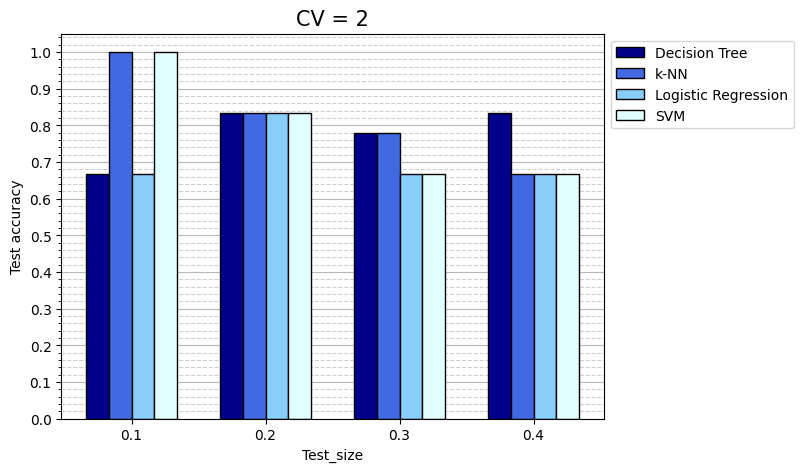

In [35]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([scores[0][0], scores[0][1], scores[0][2], scores[0][3]], "CV = 2", test_size, "Test_size", \
            np.arange(0, 1.1, 0.1), "Test accuracy", ["Decision Tree", "k-NN", "Logistic Regression", "SVM"], ["darkblue", "royalblue", "lightskyblue", "lightcyan"], 0.17, (7, 5))

0.4 has no measurable values.
0.3 has no measurable values.


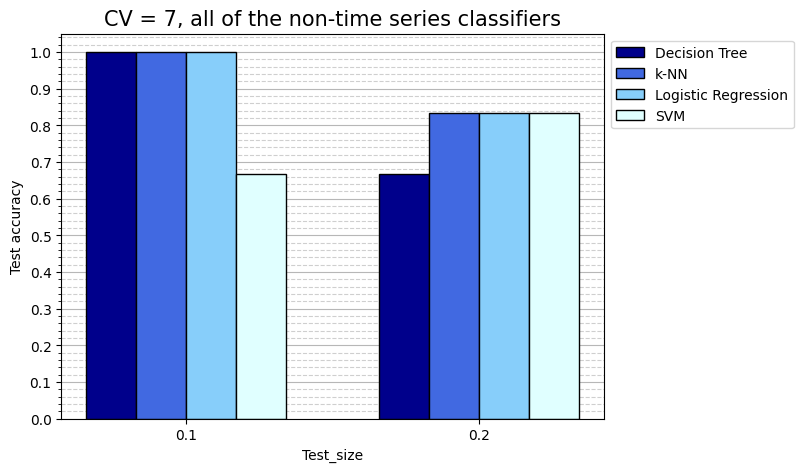

In [36]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([scores[-1][0], scores[-1][1], scores[-1][2], scores[-1][3]], "CV = 7, all of the non-time series classifiers", test_size, "Test_size", \
            np.arange(0, 1.1, 0.1), "Test accuracy", ["Decision Tree", "k-NN", "Logistic Regression", "SVM"], ["darkblue", "royalblue", "lightskyblue", "lightcyan"], 0.17, (7, 5))

#### box plot

In [151]:
#Multiple_cv_hyperparameter_tuning(cv_start, cv_end, models, metric, X, Y, test_sizes, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
scores, estimators, cvs = ptm.Multiple_cv_hyperparameter_tuning(2, 6, models, "f1_macro", NP_X_ApEn, NP_Y_ApEn_binary, [0.3], feature_names, "No", True, False, -1)

CV: 2
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 9
CV: 3
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 12
CV: 4
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 14
CV: 5
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15
CV: 6
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15


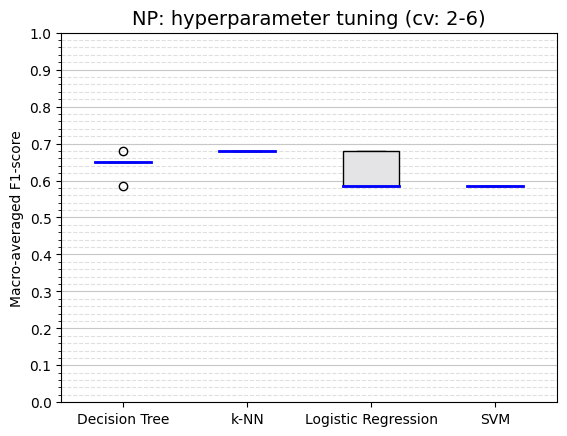

In [158]:
#Multiple_cv_param_tuning_box_plot(accuracy, title, xticks, c, ylabel, yticks)
pm.Multiple_cv_hyperparameter_tuning_box_plot(scores, 'NP: hyperparameter tuning (cv: 2-6)',  ['Decision Tree', 'k-NN', 'Logistic Regression', 'SVM'], 'blue', "Macro-averaged F1-score", np.arange(0, 1.1, 0.1))

---
## 4. Time series k-NN classifier (Full dataset)
### 4.1. Data transformation

In [14]:
#TS_df_append_to_max_len(df_list, feature_names)
TS_NP_df_list_max_len = dmm.TS_df_append_to_max_len(NP_df_list, feature_names)
TS_KT_df_list_max_len = dmm.TS_df_append_to_max_len(KT_df_list, feature_names)
TS_SU_df_list_max_len = dmm.TS_df_append_to_max_len(SU_df_list, feature_names)

#TS_df_append_truncate_to_avg_len(df_list, feature_names)
TS_NP_df_list_avg_len = dmm.TS_df_append_truncate_to_avg_len(NP_df_list, feature_names)
TS_KT_df_list_avg_len = dmm.TS_df_append_truncate_to_avg_len(KT_df_list, feature_names)
TS_SU_df_list_avg_len = dmm.TS_df_append_truncate_to_avg_len(SU_df_list, feature_names)

#TS_df_truncate_to_min_len(df_list)
TS_NP_df_list_min_len = dmm.TS_df_truncate_to_min_len(NP_df_list)
TS_KT_df_list_min_len = dmm.TS_df_truncate_to_min_len(KT_df_list)
TS_SU_df_list_min_len = dmm.TS_df_truncate_to_min_len(SU_df_list)

The maximum length: 4761
The maximum length: 3853
The maximum length: 9012
The average length: 3245
The average length: 1725
The average length: 3369
The minimum length: 1787
The minimum length: 920
The minimum length: 1779


In [15]:
#TS_Y(df_class, column_index)
TS_NP_Y_binary = dmm.TS_Y(NP_class_binary, 2)
TS_KT_Y_binary = dmm.TS_Y(KT_class_binary, 2)
TS_SU_Y_binary = dmm.TS_Y(SU_class_binary, 2)

#Multiclass version
TS_NP_Y_multi = dmm.TS_Y(NP_class_multi, 2)
TS_KT_Y_multi = dmm.TS_Y(KT_class_multi, 2)
TS_SU_Y_multi = dmm.TS_Y(SU_class_multi, 2)

---
## 5. Time series k-NN classifier (Gestures)
### 5.1. Data transformation

In [21]:
#TS_gestures_df_append_to_max_len(df_list, feature_names)
TS_NP_gestures_df_list_max_len = dmm.TS_gestures_df_append_to_max_len(NP_gestures, feature_names)
TS_NP_gestures_df_list_avg_len = dmm.TS_gestures_df_append_truncate_to_avg_len(NP_gestures, feature_names)
TS_NP_gestures_df_list_min_len = dmm.TS_gestures_df_truncate_to_min_len(NP_gestures)

#TS_gestures_df_append_truncate_to_avg_len(df_list, feature_names)
TS_KT_gestures_df_list_max_len = dmm.TS_gestures_df_append_to_max_len(KT_gestures, feature_names)
TS_KT_gestures_df_list_avg_len = dmm.TS_gestures_df_append_truncate_to_avg_len(KT_gestures, feature_names)
TS_KT_gestures_df_list_min_len = dmm.TS_gestures_df_truncate_to_min_len(KT_gestures)

#TS_gestures_df_truncate_to_min_len(df_list)
TS_SU_gestures_df_list_max_len = dmm.TS_gestures_df_append_to_max_len(SU_gestures, feature_names)
TS_SU_gestures_df_list_avg_len = dmm.TS_gestures_df_append_truncate_to_avg_len(SU_gestures, feature_names)
TS_SU_gestures_df_list_min_len = dmm.TS_gestures_df_truncate_to_min_len(SU_gestures)

In [22]:
#TS_gestures_X_Y_transform(gestures_df, df_class, column_index)
TS_NP_gestures_X_max_len, TS_NP_gestures_Y_binary, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_max_len, NP_class_binary, 2)
TS_KT_gestures_X_max_len, TS_KT_gestures_Y_binary, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_max_len, KT_class_binary, 2)
TS_SU_gestures_X_max_len, TS_SU_gestures_Y_binary, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_max_len, SU_class_binary, 2)

TS_NP_gestures_X_avg_len, TS_NP_gestures_Y_binary, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_avg_len, NP_class_binary, 2)
TS_KT_gestures_X_avg_len, TS_KT_gestures_Y_binary, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_avg_len, KT_class_binary, 2)
TS_SU_gestures_X_avg_len, TS_SU_gestures_Y_binary, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_avg_len, SU_class_binary, 2)

TS_NP_gestures_X_min_len, TS_NP_gestures_Y_binary, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_min_len, NP_class_binary, 2)
TS_KT_gestures_X_min_len, TS_KT_gestures_Y_binary, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_min_len, KT_class_binary, 2)
TS_SU_gestures_X_min_len, TS_SU_gestures_Y_binary, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_min_len, SU_class_binary, 2)

#Multiclass version
TS_NP_gestures_X_max_len, TS_NP_gestures_Y_multi, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_max_len, NP_class_multi, 2)
TS_KT_gestures_X_max_len, TS_KT_gestures_Y_multi, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_max_len, KT_class_multi, 2)
TS_SU_gestures_X_max_len, TS_SU_gestures_Y_multi, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_max_len, SU_class_multi, 2)

TS_NP_gestures_X_avg_len, TS_NP_gestures_Y_multi, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_avg_len, NP_class_multi, 2)
TS_KT_gestures_X_avg_len, TS_KT_gestures_Y_multi, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_avg_len, KT_class_multi, 2)
TS_SU_gestures_X_avg_len, TS_SU_gestures_Y_multi, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_avg_len, SU_class_multi, 2)

TS_NP_gestures_X_min_len, TS_NP_gestures_Y_multi, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_min_len, NP_class_multi, 2)
TS_KT_gestures_X_min_len, TS_KT_gestures_Y_multi, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_min_len, KT_class_multi, 2)
TS_SU_gestures_X_min_len, TS_SU_gestures_Y_multi, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_min_len, SU_class_multi, 2)

----
## 6. Hyperparameter tuning (Time series k-NN)
#### The TS_gesture_kNN_DTW_transform is not needed because it is part of the Hyperparameter_tuning function

In [331]:
from sktime.classification.distance_based import KNeighborsTimeSeriesClassifier 

In [332]:
TS_model = {
        'Time_series_kNN': {
            'model': KNeighborsTimeSeriesClassifier(distance="dtw"), #n_jobs only makes it quicker a little bit
            'params': {
                #+1: to included the last value in the range.
                'n_neighbors' : range(1, 5),
                'weights' : ['uniform', 'distance']
                      }
               }
           }

In [333]:
test_size = [0.1, 0.2, 0.3, 0.4]

In [61]:
#Hyperparameter_tuning(models, metric, X, Y, test_sizes, cv, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
TS_NP_score, TS_NP_estimator = ptm.Hyperparameter_tuning(TS_model, "accuracy", TS_NP_df_list_min_len, TS_NP_Y_binary, test_size, 5, feature_names, "No", True, True, -1)

Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 20


,Model,Validation score,Test score,Parameter
0,Time_series_kNN,0.8,1.0,KNeighborsTimeSeriesClassifier(n_neighbors=7)




Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 17


,Model,Validation score,Test score,Parameter
0,Time_series_kNN,0.82,0.833333,KNeighborsTimeSeriesClassifier(n_neighbors=7)




Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 15


,Model,Validation score,Test score,Parameter
0,Time_series_kNN,0.8,0.555556,KNeighborsTimeSeriesClassifier()




Test size (0.4): The n_neighbors parameter value has been modified. The new maximum value: 12


,Model,Validation score,Test score,Parameter
0,Time_series_kNN,0.866667,0.583333,KNeighborsTimeSeriesClassifier(n_neighbors=3)


In [29]:
#Multiple_cv_hyperparameter_tuning(cv_start, cv_end, models, metric, X, Y, test_sizes, feature_names, standardize, calculate_maximum_neighbors, show_results, n_jobs)
TS_NP_scores, TS_NP_estimators, TS_NP_cvs = ptm.Multiple_cv_hyperparameter_tuning(2, 6, TS_model, "accuracy", TS_NP_df_list_min_len, TS_NP_Y_binary, test_size, feature_names, "No", True, False, -1)

CV: 2
Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 12
Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 11
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 9
Test size (0.4): The n_neighbors parameter value has been modified. The new maximum value: 8
CV: 3
Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 16
Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 14
Test size (0.3): The n_neighbors parameter value has been modified. The new maximum value: 12
Test size (0.4): The n_neighbors parameter value has been modified. The new maximum value: 10
CV: 4
Test size (0.1): The n_neighbors parameter value has been modified. The new maximum value: 18
Test size (0.2): The n_neighbors parameter value has been modified. The new maximum value: 16
Test size (0.3): The n_neighbors parameter v

In [32]:
#Best_param_tuning_accuracies(acc, estimator, cvs, test_size, class_alg)
TS_NP_best_scores = dmm.Best_hyperparameter_tuning_scores(TS_NP_scores, TS_NP_estimators, TS_NP_cvs, test_size, ['Time_series_kNN'])

Test size: 0.1


,Classification algorithm,Best test score,Best estimator,Best cv
0,Time_series_kNN,1.0,KNeighborsTimeSeriesClassifier(n_neighbors=3),2


Test size: 0.2


,Classification algorithm,Best test score,Best estimator,Best cv
0,Time_series_kNN,0.833333,KNeighborsTimeSeriesClassifier(n_neighbors=3),2


Test size: 0.3


,Classification algorithm,Best test score,Best estimator,Best cv
0,Time_series_kNN,0.888889,KNeighborsTimeSeriesClassifier(n_neighbors=4),2


Test size: 0.4


,Classification algorithm,Best test score,Best estimator,Best cv
0,Time_series_kNN,0.583333,KNeighborsTimeSeriesClassifier(n_neighbors=3),2


----
## 7. Hyperparameter tuning (NN)

In [23]:
#diasble gpu usage, beacuse of an error
from Modules import ts_classification_algorithms_module as ts_cam
import tensorflow as tf
import os
from tensorflow import keras
%set_env TF_ENABLE_ONEDNN_OPTS=0
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

env: TF_ENABLE_ONEDNN_OPTS=0


In [24]:
from itertools import product

activations = ["relu", "elu"]
dropouts = [0.2, 0.3]
filters_list = [16, 32]
kernel_sizes = [3, 5]

param_grid = list(product(activations, dropouts, filters_list, kernel_sizes))
param_grid

[('relu', 0.2, 16, 3),
 ('relu', 0.2, 16, 5),
 ('relu', 0.2, 32, 3),
 ('relu', 0.2, 32, 5),
 ('relu', 0.3, 16, 3),
 ('relu', 0.3, 16, 5),
 ('relu', 0.3, 32, 3),
 ('relu', 0.3, 32, 5),
 ('elu', 0.2, 16, 3),
 ('elu', 0.2, 16, 5),
 ('elu', 0.2, 32, 3),
 ('elu', 0.2, 32, 5),
 ('elu', 0.3, 16, 3),
 ('elu', 0.3, 16, 5),
 ('elu', 0.3, 32, 3),
 ('elu', 0.3, 32, 5)]

In [328]:
#Hyperparameter_tuning_NN(X, Y, param_grid, epoch, batch_size, num_class, metric, validation_split, standardize, feature_names)
result = ptm.Hyperparameter_tuning_NN(TS_NP_df_list_min_len, TS_NP_Y_binary, param_grid, 100, 10, 2, "binary_accuracy", 0.3, "No", feature_names)

Futtatás 1/16: relu, 0.2, 16, 3
Restoring model weights from the end of the best epoch: 16.
Epoch 21: early stopping
1/1 [==============================] - 0s 235ms/step - loss: 0.6326 - binary_accuracy: 0.6667
Futtatás 2/16: relu, 0.2, 16, 5
Restoring model weights from the end of the best epoch: 5.
Epoch 10: early stopping
1/1 [==============================] - 1s 1s/step - loss: 0.6475 - binary_accuracy: 0.6667
Futtatás 3/16: relu, 0.2, 32, 3
Restoring model weights from the end of the best epoch: 4.
Epoch 9: early stopping
1/1 [==============================] - 0s 224ms/step - loss: 0.6426 - binary_accuracy: 0.6667
Futtatás 4/16: relu, 0.2, 32, 5
Restoring model weights from the end of the best epoch: 2.
Epoch 7: early stopping
1/1 [==============================] - 0s 242ms/step - loss: 0.6544 - binary_accuracy: 0.6667
Futtatás 5/16: relu, 0.3, 16, 3
Restoring model weights from the end of the best epoch: 16.
Epoch 21: early stopping
1/1 [==============================] - 0s 262ms

In [329]:
result

,activation,dropout,filters,kernel,test_acc
0,relu,0.2,16,3,0.666667
1,relu,0.2,16,5,0.666667
2,relu,0.2,32,3,0.666667
3,relu,0.2,32,5,0.666667
4,relu,0.3,16,3,0.777778
5,relu,0.3,16,5,0.666667
6,relu,0.3,32,3,0.666667
7,relu,0.3,32,5,0.666667
8,elu,0.2,16,3,0.666667
9,elu,0.2,16,5,0.666667


In [330]:
np.max(result["test_acc"])

0.7777777910232544